<a href="https://colab.research.google.com/github/ripon-cse24/99_days_of_coding_MLOps_With_CPC/blob/main/phase-1/day-007/day-007.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [47]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [48]:
data = pd.read_csv("/content/healthcareTest.csv")

In [49]:
data = pd.read_csv("/content/healthcareTrain.csv")

In [50]:
data.head()

,patIndex,pdc,num_ip_post,total_los_post,num_op_post,num_er_post,num_ndc_post,num_gpi6_post,adjust_total_30d_post,generic_rate_post,...,brand_cost,ratio_G_total_cost,numofgen_post,numofbrand_post,generic_cost_post,brand_cost_post,ratio_G_total_cost_post,pdc_80_flag,drug_class,patient_key
0,2393,0.500000,0,0,2,0,3,2,2.333333,1.0,...,0.000000,1.000000,3,0,39.557654,0.0,1.0,0,*ANTIDIABETICS*,322512
1,2148,0.994444,0,0,3,0,17,5,26.500000,1.0,...,19.553557,0.929937,17,0,547.646290,0.0,1.0,1,*ANTIDIABETICS*,291191
2,1799,0.472222,0,0,3,0,3,1,3.000000,1.0,...,0.000000,1.000000,3,0,8.834483,0.0,1.0,0,*ANTIDIABETICS*,251767
3,636,0.166667,0,0,0,0,2,2,2.000000,1.0,...,243.805101,NaN,2,0,8.100969,0.0,1.0,0,*ANTIDIABETICS*,80678
4,114,0.944444,0,0,3,0,12,2,12.000000,1.0,...,0.000000,1.000000,12,0,50.324328,0.0,1.0,1,*ANTIDIABETICS*,16047


In [51]:
data.tail()

,patIndex,pdc,num_ip_post,total_los_post,num_op_post,num_er_post,num_ndc_post,num_gpi6_post,adjust_total_30d_post,generic_rate_post,...,brand_cost,ratio_G_total_cost,numofgen_post,numofbrand_post,generic_cost_post,brand_cost_post,ratio_G_total_cost_post,pdc_80_flag,drug_class,patient_key
1373,3042,0.166667,1,4,5,0,4,3,3.266667,1.000000,...,0.000000,NaN,4,0,10.571707,0.000000,1.000000,0,*ANTIDIABETICS*,414581
1374,460,0.333333,0,0,0,0,6,3,7.166667,1.000000,...,75.754592,0.811928,6,0,142.484006,0.000000,1.000000,0,*ANTIDIABETICS*,58682
1375,342,0.700000,0,0,12,0,32,16,34.100000,0.648094,...,2278.143238,0.061978,22,10,206.516778,2495.125983,0.076441,0,*ANTIDIABETICS*,42540
1376,1784,0.950000,0,0,6,0,17,8,37.666667,0.796460,...,72.851186,0.942509,14,4,903.283332,486.702794,0.649851,1,*ANTIDIABETICS*,250886
1377,748,0.927778,0,0,14,1,49,15,66.666667,0.955000,...,0.000000,1.000000,46,3,2571.803777,150.341915,0.944771,1,*ANTIDIABETICS*,95201


In [52]:
data.shape

(1378, 96)

In [53]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1378 entries, 0 to 1377
Data columns (total 96 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   patIndex                    1378 non-null   int64  
 1   pdc                         1378 non-null   float64
 2   num_ip_post                 1378 non-null   int64  
 3   total_los_post              1378 non-null   int64  
 4   num_op_post                 1378 non-null   int64  
 5   num_er_post                 1378 non-null   int64  
 6   num_ndc_post                1378 non-null   int64  
 7   num_gpi6_post               1378 non-null   int64  
 8   adjust_total_30d_post       1378 non-null   float64
 9   generic_rate_post           1378 non-null   float64
 10  post_ip_flag                1378 non-null   int64  
 11  post_er_flag                1378 non-null   int64  
 12  pdc_cat                     1378 non-null   int64  
 13  post_ip_cost                1378 

In [54]:
data.describe()

,patIndex,pdc,num_ip_post,total_los_post,num_op_post,num_er_post,num_ndc_post,num_gpi6_post,adjust_total_30d_post,generic_rate_post,...,generic_cost,brand_cost,ratio_G_total_cost,numofgen_post,numofbrand_post,generic_cost_post,brand_cost_post,ratio_G_total_cost_post,pdc_80_flag,patient_key
count,1378.000000,1378.000000,1378.000000,1378.000000,1378.000000,1378.000000,1378.000000,1378.000000,1378.000000,1378.000000,...,1378.000000,1378.000000,1325.000000,1378.000000,1378.000000,1378.000000,1378.000000,1357.000000,1378.000000,1378.000000
mean,1626.484761,0.637333,0.090711,0.438316,7.309144,0.201016,17.539913,6.999274,22.963425,0.739837,...,255.323365,1038.241908,0.552423,12.677068,4.920174,309.047706,1459.533108,0.460485,0.393324,218903.561684
std,1028.639396,0.285241,0.346851,2.511449,9.082224,0.618827,12.478138,4.046301,17.298014,0.260149,...,442.705911,2871.465242,0.405481,9.834775,5.648453,494.349939,3324.206718,0.394084,0.488665,143958.815197
min,6.000000,0.022222,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,0.000000,0.000000,...,0.000000,0.000000,0.000252,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,663.000000
25%,734.500000,0.411111,0.000000,0.000000,3.000000,0.000000,9.000000,4.000000,9.666667,0.579499,...,33.483787,0.000000,0.139330,6.000000,0.000000,64.247290,0.000000,0.088645,0.000000,93215.000000
50%,1489.500000,0.666667,0.000000,0.000000,5.000000,0.000000,15.000000,6.000000,19.150000,0.793318,...,106.389911,147.892284,0.505640,10.000000,3.000000,145.242295,451.856505,0.313258,0.000000,188081.000000
75%,2486.750000,0.905556,0.000000,0.000000,9.000000,0.000000,23.000000,9.000000,31.425000,1.000000,...,282.836378,1138.244974,1.000000,17.000000,7.000000,331.925823,1899.457011,1.000000,1.000000,331391.000000
max,3534.000000,1.000000,3.000000,61.000000,180.000000,6.000000,87.000000,26.000000,111.600000,1.000000,...,5775.928188,50024.814630,1.000000,74.000000,42.000000,5855.110311,66315.417270,1.000000,1.000000,519245.000000


In [55]:
data.min(numeric_only = True)

,0
patIndex,6.000000
pdc,0.022222
num_ip_post,0.000000
total_los_post,0.000000
num_op_post,0.000000
...,...
generic_cost_post,0.000000
brand_cost_post,0.000000
ratio_G_total_cost_post,0.000000
pdc_80_flag,0.000000


In [56]:
data.max(numeric_only = True)

,0
patIndex,3534.000000
pdc,1.000000
num_ip_post,3.000000
total_los_post,61.000000
num_op_post,180.000000
...,...
generic_cost_post,5855.110311
brand_cost_post,66315.417270
ratio_G_total_cost_post,1.000000
pdc_80_flag,1.000000


In [57]:
data['patient_key'].unique()

array([322512, 291191, 251767, ...,  42540, 250886,  95201], shape=(1378,))

In [58]:
data['patient_key'].value_counts()

,count
patient_key,
322512,1
291191,1
251767,1
80678,1
16047,1
...,...
414581,1
58682,1
42540,1


In [59]:
data.isnull().sum()

,0
patIndex,0
pdc,0
num_ip_post,0
total_los_post,0
num_op_post,0
...,...
brand_cost_post,0
ratio_G_total_cost_post,21
pdc_80_flag,0
drug_class,0


In [61]:
data.fillna(data.mean(numeric_only = True), inplace = True)
data

,patIndex,pdc,num_ip_post,total_los_post,num_op_post,num_er_post,num_ndc_post,num_gpi6_post,adjust_total_30d_post,generic_rate_post,...,brand_cost,ratio_G_total_cost,numofgen_post,numofbrand_post,generic_cost_post,brand_cost_post,ratio_G_total_cost_post,pdc_80_flag,drug_class,patient_key
0,2393,0.500000,0,0,2,0,3,2,2.333333,1.000000,...,0.000000,1.000000,3,0,39.557654,0.000000,1.000000,0,*ANTIDIABETICS*,322512
1,2148,0.994444,0,0,3,0,17,5,26.500000,1.000000,...,19.553557,0.929937,17,0,547.646290,0.000000,1.000000,1,*ANTIDIABETICS*,291191
2,1799,0.472222,0,0,3,0,3,1,3.000000,1.000000,...,0.000000,1.000000,3,0,8.834483,0.000000,1.000000,0,*ANTIDIABETICS*,251767
3,636,0.166667,0,0,0,0,2,2,2.000000,1.000000,...,243.805101,0.552423,2,0,8.100969,0.000000,1.000000,0,*ANTIDIABETICS*,80678
4,114,0.944444,0,0,3,0,12,2,12.000000,1.000000,...,0.000000,1.000000,12,0,50.324328,0.000000,1.000000,1,*ANTIDIABETICS*,16047
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1373,3042,0.166667,1,4,5,0,4,3,3.266667,1.000000,...,0.000000,0.552423,4,0,10.571707,0.000000,1.000000,0,*ANTIDIABETICS*,414581
1374,460,0.333333,0,0,0,0,6,3,7.166667,1.000000,...,75.754592,0.811928,6,0,142.484006,0.000000,1.000000,0,*ANTIDIABETICS*,58682
1375,342,0.700000,0,0,12,0,32,16,34.100000,0.648094,...,2278.143238,0.061978,22,10,206.516778,2495.125983,0.076441,0,*ANTIDIABETICS*,42540
1376,1784,0.950000,0,0,6,0,17,8,37.666667,0.796460,...,72.851186,0.942509,14,4,903.283332,486.702794,0.649851,1,*ANTIDIABETICS*,250886


In [62]:
data.isnull().sum()

,0
patIndex,0
pdc,0
num_ip_post,0
total_los_post,0
num_op_post,0
...,...
brand_cost_post,0
ratio_G_total_cost_post,0
pdc_80_flag,0
drug_class,0


In [63]:
data.mean(numeric_only = True)

,0
patIndex,1626.484761
pdc,0.637333
num_ip_post,0.090711
total_los_post,0.438316
num_op_post,7.309144
...,...
generic_cost_post,309.047706
brand_cost_post,1459.533108
ratio_G_total_cost_post,0.460485
pdc_80_flag,0.393324


In [64]:
data.duplicated().sum()

np.int64(0)

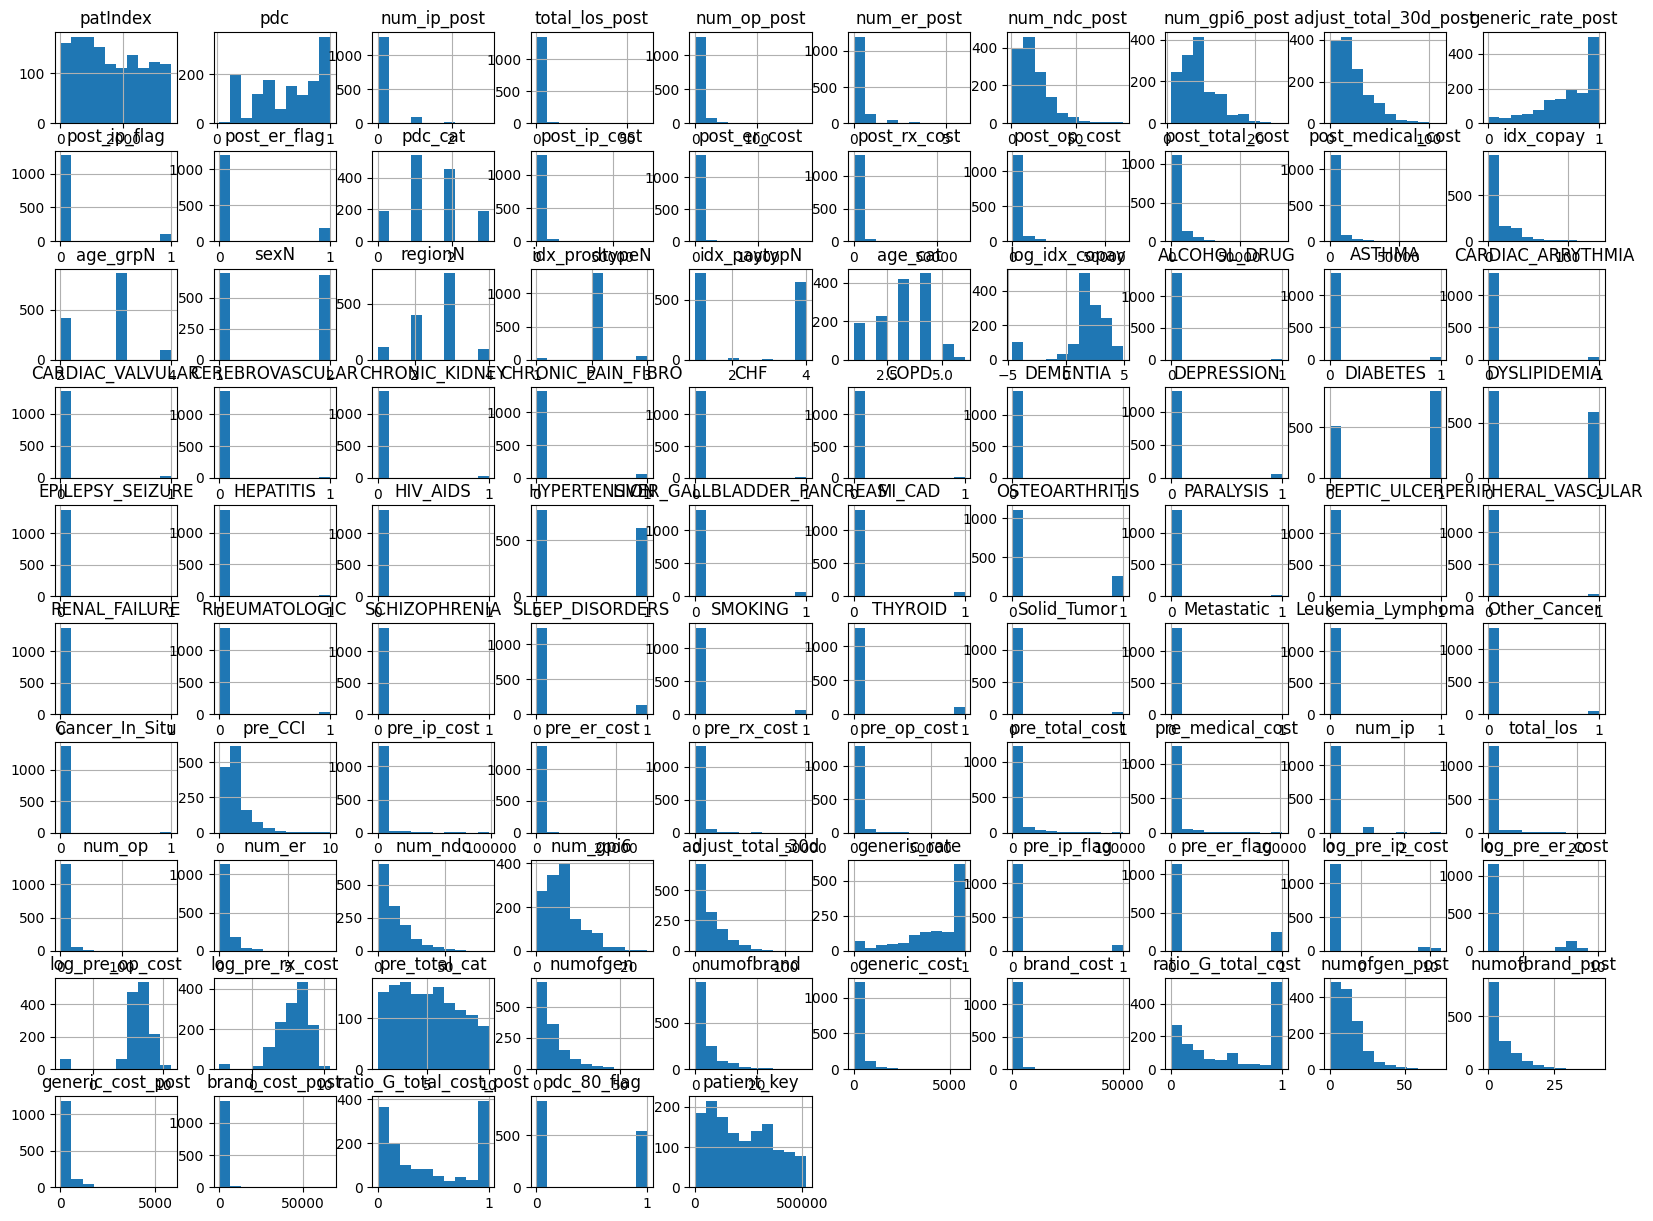

In [65]:
data.hist(figsize = (20, 15))
plt.show()